In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, root_mean_squared_error, mean_absolute_error

In [2]:
df = pd.read_csv(r"/Users/kashvivirmani/Desktop/Delhi_UHI_Project/Data/Processed/cleaned_dataset.csv")
df.head()

,Latitude,Longitude,AirTemp,DistanceToWater,Elevation,Humidity,LST,LULC,MNDWI,NDBI,NDVI,Population,Slope,WindSpeed,LULC_Name
0,28.632720,77.204349,32.490555,1065.082156,223,28.763419,41.820506,6,-0.103358,-0.061668,0.161954,190.287857,3.489779,1.422401,Built Area
1,28.614477,77.114090,32.618237,4417.420062,219,28.276358,46.014417,6,-0.089072,-0.004090,0.071271,318.664734,1.854334,1.422094,Built Area
2,28.783908,77.106962,32.277801,56.568542,211,29.923939,44.336169,0,-0.086957,-0.014011,0.089721,0.000000,1.406886,1.355455,Water
3,28.660692,77.147372,32.479869,1059.056184,216,29.162266,45.623053,6,-0.079266,-0.051205,0.125391,268.919067,2.307262,1.391453,Built Area
4,28.814437,76.991782,32.366906,1223.764683,226,29.204621,50.153639,7,-0.151679,0.025338,0.100419,0.000000,4.263645,1.359317,Bare Ground


In [3]:
df = df.drop(columns = ["Latitude","Longitude","LULC_Name"])

In [4]:
df.sample(10)

,AirTemp,DistanceToWater,Elevation,Humidity,LST,LULC,MNDWI,NDBI,NDVI,Population,Slope,WindSpeed
3132,32.594268,948.261567,214,28.426848,46.862086,6,-0.142066,0.008320,0.107624,139.110687,1.406106,1.390905
1214,32.327412,1681.903683,218,29.849901,47.663611,6,-0.080235,0.007949,0.054195,507.850067,4.627367,1.385324
1072,32.517846,5405.922678,231,27.955163,44.255845,6,-0.128233,-0.055541,0.177286,260.889465,3.851399,1.449525
9354,32.253426,1856.017241,211,30.109102,46.275895,6,-0.094185,0.010967,0.055143,663.440491,1.406435,1.373098
2892,32.594268,721.110255,213,28.426848,51.951517,4,-0.182188,0.037979,0.109028,0.352406,1.854334,1.390905
95,32.641388,4129.309870,283,27.635627,49.748604,6,-0.171072,-0.017922,0.168478,0.000000,2.132948,1.465776
5703,32.490555,4522.123395,243,28.763419,43.404758,1,-0.144082,-0.011686,0.153602,0.000000,1.405620,1.422401
9139,32.594268,840.951842,211,28.426848,46.426288,4,-0.152199,-0.118938,0.268612,0.000000,2.810046,1.390905
3311,32.618237,3120.256400,213,28.276358,43.871318,6,-0.159073,-0.041812,0.191804,12.131183,3.489059,1.422094
2009,32.277801,2505.992817,214,29.923939,41.417180,1,-0.126992,-0.068344,0.203532,0.000000,2.134953,1.355455


In [5]:
X = df.drop("LST", axis=1)
y = df["LST"]

In [6]:
# Train test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=43
)

In [7]:
# Standardization
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [8]:
lr = LinearRegression()
lr.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](11,)","[-0.44, 0.19,-0.3 ,...,-0.23, 0.07,-1.13]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,46.66
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,11
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(11)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](11,)","[159.69,127.6 ,112.42,..., 31.55, 12.58, 7.68]"


In [9]:
y_pred_train = lr.predict(X_train)
y_pred_test = lr.predict(X_test)

print(f"r2_score of training data = {r2_score(y_train, y_pred_train)}")
print(f"r2_score of testing data = {r2_score(y_test, y_pred_test)}")

print(f"root_mean_squared_error of training data = {root_mean_squared_error(y_train, y_pred_train)}")
print(f"root_mean_squared_error of testing data = {root_mean_squared_error(y_test, y_pred_test)}")
print(f"mean_absolute_error of testing data = {mean_absolute_error(y_test, y_pred_test)}")

r2_score of training data = 0.7435054296055481
r2_score of testing data = 0.7378327234893977
root_mean_squared_error of training data = 1.7229034978442974
root_mean_squared_error of testing data = 1.7182866419321128
mean_absolute_error of testing data = 1.3299381864095279


# Visualization

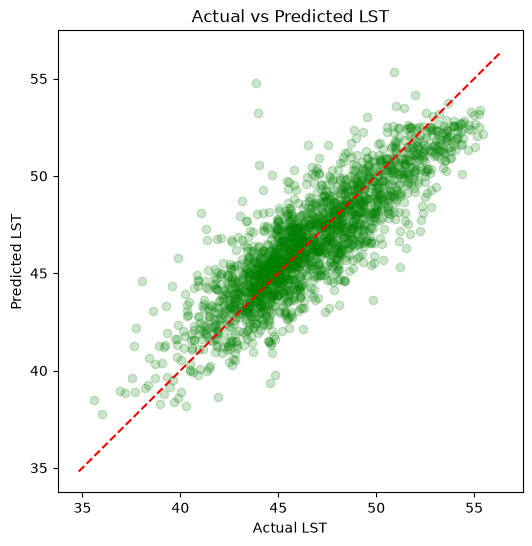

In [10]:
# Actual vs Predictedplt

plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred_test,c="green", alpha=0.2)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--')
plt.xlabel("Actual LST")
plt.ylabel("Predicted LST")
plt.title("Actual vs Predicted LST")
plt.show()

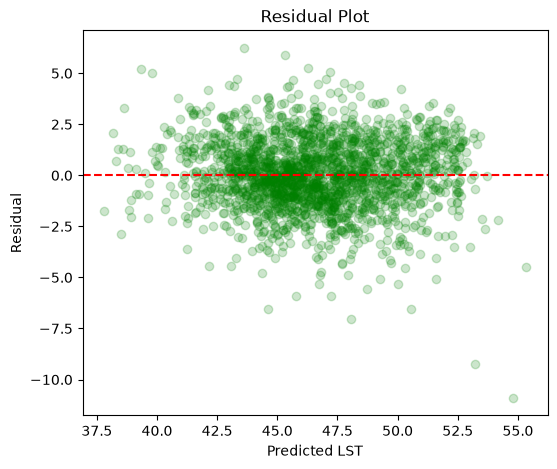

In [11]:
residuals = y_test - y_pred_test

plt.figure(figsize=(6,5))
plt.scatter(y_pred_test, residuals,c="green", alpha=0.2)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Predicted LST")
plt.ylabel("Residual")
plt.title("Residual Plot")
plt.show()